# DL-030: Neural Network vs Traditional ML Comparison
**Student:** Priyansh Singh | **Course:** B.Tech CSE (Deep Learning) | **Institution:** Invertis University

**Research question:** Does a neural network give a real advantage over traditional machine learning on a small tabular classification dataset?

**Dataset:** Breast Cancer Wisconsin (Diagnostic) - 569 samples, 30 numeric features, 2 classes (malignant / benign). Built into scikit-learn.

**Models:** Logistic Regression, Random Forest, SVM (traditional) vs a Keras MLP (neural network).

Run all cells top to bottom in Google Colab (Runtime > Run all). Every number in the report must come from your own run.

## 1. Imports and setup

In [13]:
import time, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
sns.set_theme(style="whitegrid")
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 2. Load data and explore (EDA)

In [14]:
data = load_breast_cancer(as_frame=True)
df = data.frame
print(df.shape)
print(df['target'].value_counts().rename({0: 'malignant', 1: 'benign'}))
df.head()

(569, 31)
target
benign       357
malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


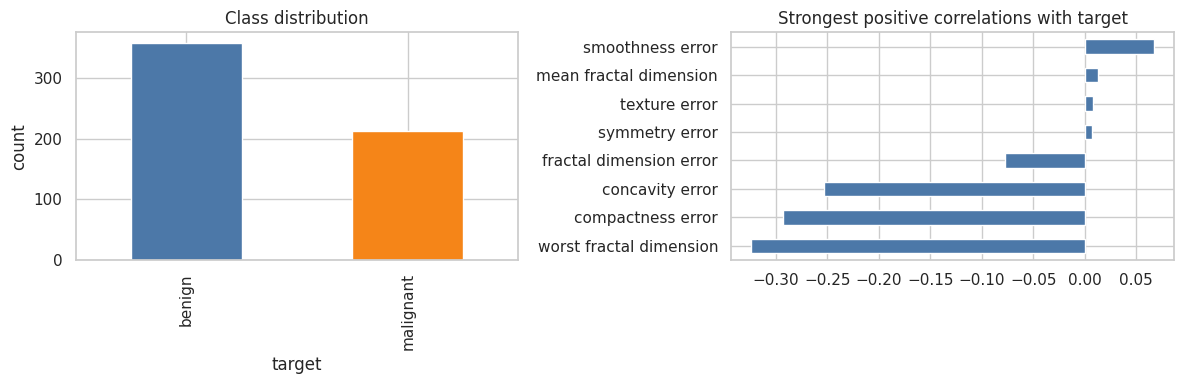

Missing values: 0


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df['target'].map({0: 'malignant', 1: 'benign'}).value_counts().plot.bar(ax=ax[0], color=['#4c78a8', '#f58518'])
ax[0].set_title('Class distribution'); ax[0].set_ylabel('count')
corr = df.corr()['target'].drop('target').sort_values()
corr.tail(8).plot.barh(ax=ax[1], color='#4c78a8'); ax[1].set_title('Strongest positive correlations with target')
plt.tight_layout(); plt.show()
print("Missing values:", int(df.isna().sum().sum()))

## 3. Train/test split
One stratified 80/20 split is shared by **all** models, so the comparison is fair. Scaling is fitted on the training set only to avoid data leakage.

In [16]:
X, y = data.data.values, data.target.values
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (455, 30) Test: (114, 30)


## 4. Traditional ML models

In [17]:
results, preds = [], {}

def evaluate(name, y_true, y_pred, train_time):
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "Train time (s)": train_time})
    preds[name] = y_pred

traditional = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, random_state=SEED), True),
    "Random Forest":       (RandomForestClassifier(n_estimators=200, random_state=SEED), False),
    "SVM (RBF)":           (SVC(random_state=SEED), True),
}
for name, (model, needs_scaling) in traditional.items():
    Xa, Xb = (X_train_s, X_test_s) if needs_scaling else (X_train, X_test)
    t0 = time.time(); model.fit(Xa, y_train); dt = time.time() - t0
    evaluate(name, y_test, model.predict(Xb), dt)
pd.DataFrame(results).round(4)

,Model,Accuracy,Precision,Recall,F1,Train time (s)
0,Logistic Regression,0.9825,0.9861,0.9861,0.9861,0.0115
1,Random Forest,0.9561,0.9589,0.9722,0.9655,0.9268
2,SVM (RBF),0.9825,0.9861,0.9861,0.9861,0.0085


## 5. Neural network (Keras MLP)
Architecture: 30 inputs -> Dense(32, ReLU) -> Dropout(0.2) -> Dense(16, ReLU) -> Dense(1, sigmoid).
Loss: binary cross-entropy. Optimizer: Adam. Early stopping watches validation loss to reduce overfitting.

In [18]:
def build_mlp(n_features):
    model = keras.Sequential([
        layers.Input(shape=(n_features,)),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="binary_crossentropy", metrics=["accuracy"])
    return model

mlp = build_mlp(X_train_s.shape[1])
mlp.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_18 (Dense)                │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,537 (6.00 KB)

 Trainable params: 1,537 (6.00 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
t0 = time.time()
history = mlp.fit(X_train_s, y_train, validation_split=0.2, epochs=200,
                  batch_size=16, callbacks=[early], verbose=0)
dt = time.time() - t0
y_prob = mlp.predict(X_test_s, verbose=0).ravel()
evaluate("Neural Network (MLP)", y_test, (y_prob >= 0.5).astype(int), dt)
print("Stopped at epoch:", len(history.history["loss"]))

Stopped at epoch: 102


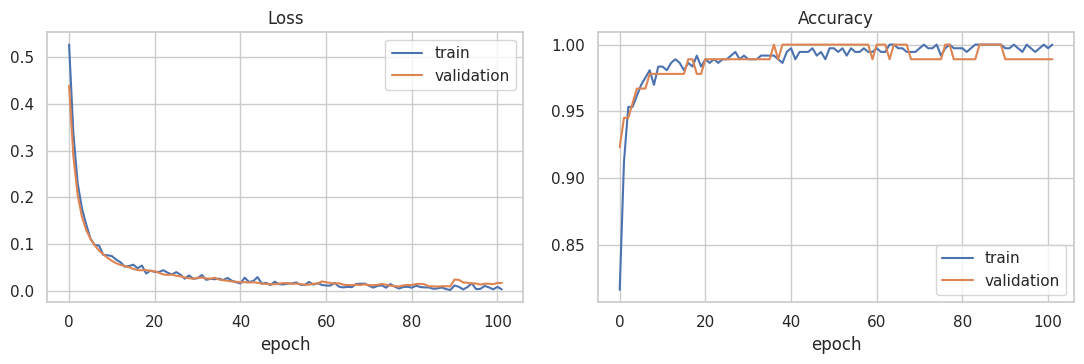

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(history.history["loss"], label="train"); ax[0].plot(history.history["val_loss"], label="validation")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train"); ax[1].plot(history.history["val_accuracy"], label="validation")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

## 6. Comparison of all models

,Accuracy,Precision,Recall,F1,Train time (s)
Model,,,,,
Logistic Regression,0.9825,0.9861,0.9861,0.9861,0.0554
Random Forest,0.9561,0.9589,0.9722,0.9655,1.5761
SVM (RBF),0.9825,0.9861,0.9861,0.9861,0.0167
Neural Network (MLP),0.9649,0.9857,0.9583,0.9718,25.1465


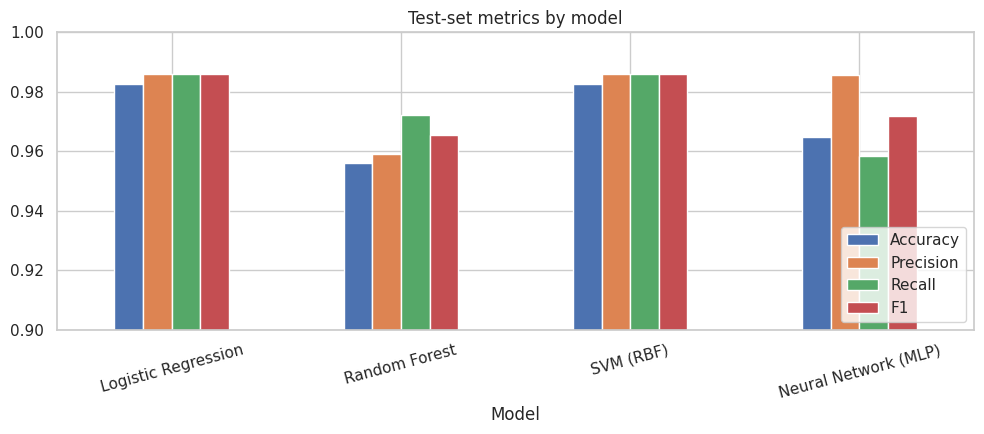

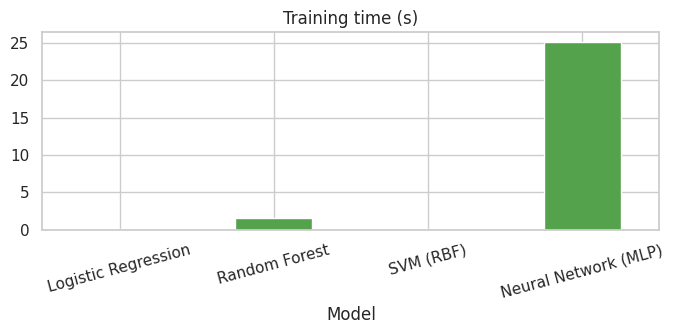

In [9]:
res = pd.DataFrame(results).set_index("Model")
display(res.round(4))
res.to_csv("model_comparison.csv")

res[["Accuracy", "Precision", "Recall", "F1"]].plot.bar(figsize=(10, 4.5), ylim=(0.9, 1.0))
plt.title("Test-set metrics by model"); plt.xticks(rotation=15); plt.legend(loc="lower right")
plt.tight_layout(); plt.show()

res["Train time (s)"].plot.bar(figsize=(7, 3.5), color="#54a24b")
plt.title("Training time (s)"); plt.xticks(rotation=15); plt.tight_layout(); plt.show()

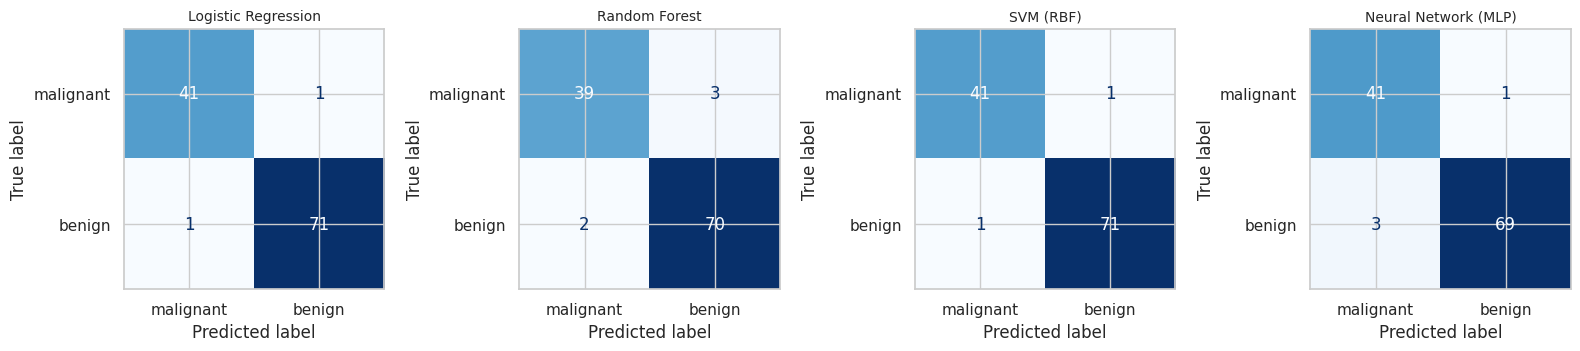

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, (name, p) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p),
        display_labels=["malignant", "benign"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name, fontsize=10)
plt.tight_layout(); plt.show()

## 7. Robustness check: 5-fold cross-validation (traditional models)
The test set has only 114 samples, so one split can be misleading. Cross-validation gives a steadier estimate.

In [11]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []
cv_models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=SEED),
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC()),
}
for name, m in cv_models.items():
    s = cross_val_score(m, X, y, cv=skf, scoring="accuracy")
    cv_rows.append({"Model": name, "CV mean acc": s.mean(), "CV std": s.std()})
pd.DataFrame(cv_rows).round(4)

,Model,CV mean acc,CV std
0,Logistic Regression,0.9737,0.0166
1,Random Forest,0.9543,0.0102
2,SVM (RBF),0.9772,0.0163


In [12]:
# Same 5-fold CV for the neural network (re-trained from scratch every fold)
nn_scores = []
for tr, va in skf.split(X, y):
    sc = StandardScaler().fit(X[tr])
    m = build_mlp(X.shape[1])
    m.fit(sc.transform(X[tr]), y[tr], validation_split=0.2, epochs=200, batch_size=16,
          callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)],
          verbose=0)
    p = (m.predict(sc.transform(X[va]), verbose=0).ravel() >= 0.5).astype(int)
    nn_scores.append(accuracy_score(y[va], p))
print("Neural Network CV mean acc: %.4f  std: %.4f" % (np.mean(nn_scores), np.std(nn_scores)))

Neural Network CV mean acc: 0.9667  std: 0.0170


## 8. Conclusion (fill in from YOUR printed results)
- Which model had the best test accuracy / F1? Which had the best recall (fewest missed malignant cases)?
- Was the neural network meaningfully better than Logistic Regression, or just similar?
- Compare training time. Is the extra cost of the neural network justified?
- State limitations: small dataset (569 rows), one split, results can change with a different seed.

**Typical finding on small tabular data:** simple models like Logistic Regression and SVM match or beat neural networks, which usually need more data to show an advantage. Confirm this against your own numbers.